# Importar Datos

In [1]:
# Importar librerías
import pandas
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Lectura de los datos
data = pandas.read_csv("../IMDb_Extensive_Dataset/IMDb movies.csv")

/opt/conda/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (3) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [3]:
# Imprimimos información de las variables para saber cuales son numéricas, strings, etc. 
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85855 entries, 0 to 85854
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   imdb_title_id          85855 non-null  object 
 1   title                  85855 non-null  object 
 2   original_title         85855 non-null  object 
 3   year                   85855 non-null  object 
 4   date_published         85855 non-null  object 
 5   genre                  85855 non-null  object 
 6   duration               85855 non-null  int64  
 7   country                85791 non-null  object 
 8   language               85022 non-null  object 
 9   director               85768 non-null  object 
 10  writer                 84283 non-null  object 
 11  production_company     81400 non-null  object 
 12  actors                 85786 non-null  object 
 13  description            83740 non-null  object 
 14  avg_vote               85855 non-null  float64
 15  vo

# Limpieza y nuevas variables

In [4]:
# Limpieza de Género. Hace dummies para cada género distinto. 
generos = []
for j in data['genre'].dropna().str.rsplit(', '):
    for i in j:
        if i not in generos:
            generos.append(i)

generos_names = ["{}{}".format(i,"_Genre") for i in generos]

aux = []
for i in range(len(generos)):
    aux.append(pandas.Series.tolist(data['genre'].str.contains(generos[i], regex = False)))

Genres = pandas.DataFrame.transpose(pandas.DataFrame(aux, index = generos))

Genres.columns = generos_names

In [5]:
# Limpieza de Lenguaje. Hace dummies para cada lenguaje distinto. 
# Faltaría hacer una categoría de otros para reducir la cantidad de variables.
lenguaje = []
for j in data['language'].dropna().str.rsplit(', '):
    for i in j:
        if i not in lenguaje:
            lenguaje.append(i)

lenguaje_names = ["{}{}".format(i,"_Language") for i in lenguaje]

aux = []
for i in range(len(lenguaje)):
    aux.append(pandas.Series.tolist(data['language'].str.contains(lenguaje[i], regex = False)))

Lenguajes = pandas.DataFrame.transpose(pandas.DataFrame(aux, index = lenguaje))
Lenguajes.columns = lenguaje_names

In [6]:
# Limpieza de País. Hace dummies para cada pais distinto. 
# Faltaría hacer una categoría de otros para reducir la cantidad de variables.
pais = []
for j in data['country'].dropna().str.rsplit(', '):
    for i in j:
        if i not in pais:
            pais.append(i)

pais_names = ["{}{}".format(i,"_Country") for i in pais]

aux = []
for i in range(len(pais)):
    aux.append(pandas.Series.tolist(data['country'].str.contains(pais[i], regex = False)))

Paises = pandas.DataFrame.transpose(pandas.DataFrame(aux, index = pais))
Paises.columns = pais_names

In [7]:
# Unir los dataframes, para que incluya todas las de generos distintos (los dummies)
data = pandas.concat([data, Genres], axis=1)
data = pandas.concat([data, Lenguajes], axis=1)
data = pandas.concat([data, Paises], axis=1)
# Quitamos todas las observaciones con NAs
data = pandas.DataFrame.dropna(data)

In [8]:
# Categóricas
# Año
data["year"] = data["year"].astype('category').cat.codes

# Production Company
data["production_company"] = data["production_company"].astype('category').cat.codes
data.loc[data['production_company'].isin((data['production_company'].value_counts() \
                                          [data['production_company'].value_counts() < 35]).index), \
                                          'production_company'] = 0

# Director
data["director"] = data["director"].astype('category').cat.codes
data.loc[data['director'].isin((data['director'].value_counts() \
                                [data['director'].value_counts() < 5]).index), 'director'] = 0

# Writer
data["writer"] = data["writer"].astype('category').cat.codes
data.loc[data['writer'].isin((data['writer'].value_counts() \
                                [data['writer'].value_counts() < 5]).index), 'writer'] = 0

In [9]:
data = pandas.get_dummies(data, columns=['director',"writer","production_company"])

In [10]:
# USA Gross Income a log de eso limpio
usa_income_series = pandas.Series.dropna(data['usa_gross_income'])
usa_income_series = usa_income_series[usa_income_series.astype('str').str.contains("$", regex = False)]
usa_income_series = pandas.to_numeric(pandas.Series(usa_income_series.astype(str).str.extract('(\d+)')[0]))
data["usa_gross_income"] = np.log(usa_income_series)

In [11]:
# Worldwide Gross Income a log de eso limpio
worldwide_income_series = pandas.Series.dropna(data['worlwide_gross_income'])
worldwide_income_series = worldwide_income_series[worldwide_income_series.astype('str').str.contains("$", regex = False)]
worldwide_income_series = pandas.to_numeric(pandas.Series(worldwide_income_series.astype(str).str.extract('(\d+)')[0]))
data["worlwide_gross_income"] = np.log(worldwide_income_series)

In [12]:
# Budget a log, pero limpio
budget_series = pandas.Series.dropna(data['budget'])
budget_series = budget_series[budget_series.astype('str').str.contains("$", regex = False)]
budget_series = pandas.to_numeric(pandas.Series(budget_series.astype(str).str.extract('(\d+)')[0]))
data["budget"] = budget_series
data["budget"] = data["budget"].fillna(0)

In [13]:
data["gross_income"] = data["worlwide_gross_income"] + data["usa_gross_income"]

<AxesSubplot:xlabel='duration', ylabel='gross_income'>

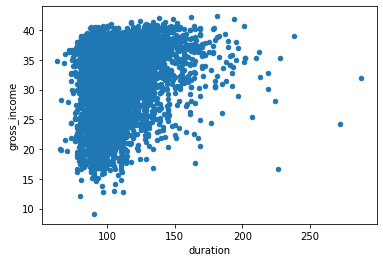

In [14]:
data.plot.scatter(x = "duration", y = "gross_income")

# Categoricas a dummies

In [15]:
director_list = [s for s in list(data.columns) if "director" in s]
writer_list = [s for s in list(data.columns) if "writer" in s]
prodcomp_list = [s for s in list(data.columns) if "production" in s]

# Separamos en explicativas y objetivo, y testing y train, y validación

In [16]:
# Separa la base de datos, usa la variable "quality" como variable objetivo, y
# todas las demás variables como variables explicativas
X = data[["duration", "avg_vote", "votes", \
          "budget","metascore", "reviews_from_users", "reviews_from_critics"] \
         + generos_names + lenguaje_names + pais_names \
         + director_list + writer_list + prodcomp_list].to_numpy()
Y = data["gross_income"].to_numpy()

print(X.shape)
print(Y.shape)

(6616, 895)
(6616,)


In [17]:
# Separamos en training, validación y testing
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.1, random_state=42)

print(f"{len(x_train)} training samples")
print(f"{len(x_val)} validation samples")
print(f"{len(x_test)} test samples")

4762 training samples
530 validation samples
1324 test samples


# Setup para modelar

In [18]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

# Usa kNN de scikit learn
from sklearn.neighbors import KNeighborsRegressor

# Usando Random Forest de scikit learn
from sklearn.tree import DecisionTreeRegressor

# Usando SVR de scikit learn
from sklearn.svm import SVR

# Modelo de KNN

In [19]:
# Crea un objeto y entrenalo
kNN_regressor = KNeighborsRegressor(n_neighbors=6)
kNN_regressor.fit(x_train, y_train)

KNeighborsRegressor(n_neighbors=6)

In [20]:
# Predict on the validation set
y_val_hat = kNN_regressor.predict(x_val)
print("prediction: ", y_val_hat[:20])
print("true label: ", y_val[:20])

prediction:  [30.45900506 32.77809525 35.08101898 20.50581334 33.18632706 24.89680102
 32.96840135 34.44298814 34.62782093 33.81639853 33.35614755 29.67324552
 35.12608403 38.47019113 37.32338071 19.91172554 32.78451539 26.4765398
 28.81110086 34.87612148]
true label:  [33.61100799 33.45919768 33.82770811 19.07568788 33.3110332  22.22022779
 33.87879205 36.63961584 33.92198318 35.9230297  36.77521312 22.59535135
 35.10137753 38.35737776 37.87947724 24.18014479 33.97950575 23.15379015
 30.56216544 32.86358718]


In [21]:
# Report accuracy performance on the training and validation set
print(f"Performance on the training set: {kNN_regressor.score(x_train, y_train):.3f}")
print(f"Performance on the validation set: {kNN_regressor.score(x_val, y_val):.3f}")

Performance on the training set: 0.735
Performance on the validation set: 0.621


In [22]:
print(mean_squared_error(y_val_hat, y_val))
print(mean_absolute_error(y_val_hat, y_val))

10.46152111716515
2.355110961013924


# Modelo Decision Tree Regressor

In [23]:
clf = DecisionTreeRegressor()
clf = clf.fit(x_train, y_train)

In [24]:
# Predict on the validation set
y_val_hat = clf.predict(x_val)
print("prediction: ", y_val_hat[:20])
print("true label: ", y_val[:20])

prediction:  [32.44159074 34.99463345 35.09900649 20.90587512 30.60314228 25.08759534
 32.68195039 36.20384545 36.51814337 33.94640121 33.2760479  24.23114675
 36.81048158 38.46117506 37.30883494 28.87737898 33.89060074 22.57157015
 34.0091454  32.58813227]
true label:  [33.61100799 33.45919768 33.82770811 19.07568788 33.3110332  22.22022779
 33.87879205 36.63961584 33.92198318 35.9230297  36.77521312 22.59535135
 35.10137753 38.35737776 37.87947724 24.18014479 33.97950575 23.15379015
 30.56216544 32.86358718]


In [25]:
# Report accuracy performance on the training and validation set
print(f"Performance on the training set: {clf.score(x_train, y_train):.3f}")
print(f"Performance on the validation set: {clf.score(x_val, y_val):.3f}")

Performance on the training set: 1.000
Performance on the validation set: 0.485


In [26]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
print(mean_squared_error(y_val_hat, y_val))
print(mean_absolute_error(y_val_hat, y_val))

14.209141288498664
2.504553929907864


# Modelo SVR

In [27]:
svr = SVR()
svr = svr.fit(x_train, y_train)

In [28]:
# Predict on the validation set
y_val_hat = svr.predict(x_val)
print("prediction: ", y_val_hat[:20])
print("true label: ", y_val[:20])

prediction:  [33.17337358 34.25158311 35.40297399 27.95291134 34.25434583 28.98089343
 34.97421263 33.18715126 36.07273351 35.26487542 32.35290061 33.17085196
 34.86084289 37.79708014 36.65538197 28.05723263 35.6697941  30.70418231
 31.05973937 35.69746799]
true label:  [33.61100799 33.45919768 33.82770811 19.07568788 33.3110332  22.22022779
 33.87879205 36.63961584 33.92198318 35.9230297  36.77521312 22.59535135
 35.10137753 38.35737776 37.87947724 24.18014479 33.97950575 23.15379015
 30.56216544 32.86358718]


In [29]:
# Report accuracy performance on the training and validation set
print(f"Performance on the training set: {svr.score(x_train, y_train):.3f}")
print(f"Performance on the validation set: {svr.score(x_val, y_val):.3f}")

Performance on the training set: 0.472
Performance on the validation set: 0.455


# Probando otros modelos y tuning

In [41]:
# Import models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_percentage_error

In [42]:
# Set print options for decimal values
np.set_printoptions(formatter={'float': lambda x: "{0:0.2f}".format(x)})

In [43]:
# Separación en training, validación y testing
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.1, random_state=42)

print(f"{len(x_train)} training samples")
print(f"{len(x_val)} validation samples")
print(f"{len(x_test)} test samples")

4762 training samples
530 validation samples
1324 test samples


In [45]:
# Grid search over kNN regressor
parameters = {'n_neighbors': range(1, 2), 'weights': ['uniform', 'distance'],
              'p': range(1, 2), 'algorithm': ['auto', 'ball_tree']}

gs_model = GridSearchCV(KNeighborsRegressor(), parameters, n_jobs=-1, scoring='mean_absolute_percentage_error')
gs_model.fit(x_train, y_train)

print(f"Best score: {gs_model.best_score_:.3f}")
print(f"Best params: {gs_model.best_params_}")

ValueError: 'metrics.mean_absolute_percentage_error' is not a valid scoring value. Use sorted(sklearn.metrics.SCORERS.keys()) to get valid options.

In [35]:
# Predict on validation data, and print score
y_val_hat = gs_model.best_estimator_.predict(x_val)

print("prediction: ", y_val_hat[:10])
print("true label: ", y_val[:10].astype('float'))

print(f"MSE on the training set: {mse(gs_model.best_estimator_.predict(x_train), y_train):.3f}")
print(f"MSE on the validation set: {mse(gs_model.best_estimator_.predict(x_val), y_val):.3f}")
print(f"MSE on the test set: {mse(gs_model.best_estimator_.predict(x_test), y_test):.3f}")

AttributeError: 'GridSearchCV' object has no attribute 'best_estimator_'

In [ ]:
# Grid search over Lasso Regularized Linear Regression
parameters = {'normalize': ['True', 'False'], 'alpha':np.logspace(-10, 0,base = np.e, num=100, endpoint = True).tolist()}

gs_model = GridSearchCV(Lasso(alpha = 0.1), parameters, n_jobs=-1, scoring='r2')
gs_model.fit(x_train, y_train)

print(f"Best score: {gs_model.best_score_:.3f}")
print(f"Best params: {gs_model.best_params_}")

In [ ]:
# Predict on validation data, and print score
y_val_hat = gs_model.best_estimator_.predict(x_val)

print("prediction: ", y_val_hat[:10])
print("true label: ", y_val[:10].astype('float'))

print(f"MSE on the training set: {mse(gs_model.best_estimator_.predict(x_train), y_train):.3f}")
print(f"MSE on the validation set: {mse(gs_model.best_estimator_.predict(x_val), y_val):.3f}")
print(f"MSE on the test set: {mse(gs_model.best_estimator_.predict(x_test), y_test):.3f}")

In [ ]:
# Grid search over SVR
parameters = {'kernel': ['linear', 'poly', 'rbf'], 'degree': range(1, 4),
              'coef0': [0.0, 0.001, 0.01, 0.1, 1.0], 'C': [0.001, 0.01, 0.1, 1.0, 10, 100]}

gs_model = GridSearchCV(SVR(), parameters, cv=2, n_jobs=-1, verbose=2)
gs_model.fit(x_train, y_train)

print(f"Best score: {gs_model.best_score_:.3f}")
print(f"Best params: {gs_model.best_params_}")

In [ ]:
# Predict on validation data, and print score
y_val_hat = gs_model.best_estimator_.predict(x_val)

print("prediction: ", y_val_hat[:10])
print("true label: ", y_val[:10].astype('float'))

print(f"MSE on the training set: {mse(gs_model.best_estimator_.predict(x_train), y_train):.3f}")
print(f"MSE on the validation set: {mse(gs_model.best_estimator_.predict(x_val), y_val):.3f}")
print(f"MSE on the test set: {mse(gs_model.best_estimator_.predict(x_test), y_test):.3f}")